In [ ]:

# ЛАБОРАТОРНАЯ РАБОТА №3
# Яшков П. А. — Вариант №4
# YOLO11s — обнаружение котов

!pip -q install -U ultralytics pyyaml

import torch
import ultralytics
from pathlib import Path
from google.colab import drive

print("=" * 55)
print("ЛАБОРАТОРНАЯ РАБОТА №3")
print("Яшков П. А. — Вариант №4")
print("YOLO11s — обнаружение котов")
print("=" * 55)

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)

DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("Устройство:", DEVICE)

if torch.cuda.is_available():
    print("Видеокарта:", torch.cuda.get_device_name(0))
else:
    print("ВНИМАНИЕ! GPU не обнаружен!")

# Подключение Google Drive
drive.mount("/content/drive")

# Создание папок лабораторной
ROOT = Path("/content/drive/MyDrive/OIIS_LR3_Yashkov")
DATA_DIR = ROOT / "dataset"
MODELS_DIR = ROOT / "models"
RESULTS_DIR = ROOT / "results"
PLOTS_DIR = RESULTS_DIR / "plots"
PREDICTIONS_DIR = RESULTS_DIR / "predictions"

for folder in [
    DATA_DIR,
    MODELS_DIR,
    RESULTS_DIR,
    PLOTS_DIR,
    PREDICTIONS_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("=" * 55)
print("Google Drive подключён!")
print("Рабочие папки созданы!")
print("Среда готова к работе!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
ЛАБОРАТОРНАЯ РАБОТА №3
Яшков П. А. — Вариант №4
YOLO11s — обнаружение котов
PyTorch: 2.14.1+cu130
Ultralytics: 8.4.218
Устройство: 0
Видеокарта: Tesla T4
Mounted at /content/drive
Google Drive подключён!
Рабочие папки созданы!
Среда готова к работе!


In [ ]:

from ultralytics import YOLO
import torch

# Загрузка предобученной модели YOLO11s
model = YOLO("yolo11s.pt")

# Проверяем модель
print("=" * 55)
print("ПРОВЕРКА МОДЕЛИ YOLO11s")
print("=" * 55)

print("Название модели: YOLO11s")
print("Задача: Object Detection")
print("Устройство:", DEVICE)

model.info()

# Проверяем наличие класса cat
classes = model.names

cat_classes = {
    index: name
    for index, name in classes.items()
    if name.lower() == "cat"
}

print("\nКоличество исходных классов:", len(classes))
print("Класс cat:", cat_classes)

# Проверяем сохранение весов
MODEL_PATH = MODELS_DIR / "yolo11s_pretrained.pt"

import shutil

shutil.copy2("yolo11s.pt", MODEL_PATH)

print("\nПредобученные веса сохранены:")
print(MODEL_PATH)
print("\nМодель готова к дальнейшей работе!")


ПРОВЕРКА МОДЕЛИ YOLO11s
Название модели: YOLO11s
Задача: Object Detection
Устройство: 0
YOLO11s summary: 181 layers, 9,458,752 parameters, 0 gradients, 21.8 GFLOPs

Количество исходных классов: 80
Класс cat: {15: 'cat'}

Предобученные веса сохранены:
/content/drive/MyDrive/OIIS_LR3_Yashkov/models/yolo11s_pretrained.pt

Модель готова к дальнейшей работе!


In [ ]:

print("ПРОВЕРКА СТРУКТУРЫ ЛАБОРАТОРНОЙ №3")
print("=" * 55)

folders = {
    "Датасет": DATA_DIR,
    "Модели": MODELS_DIR,
    "Результаты": RESULTS_DIR,
    "Графики": PLOTS_DIR,
    "Предсказания": PREDICTIONS_DIR
}

for name, path in folders.items():
    status = "OK" if path.exists() else "ОШИБКА"
    print(f"{name}: {status}")

print("\nGPU:", torch.cuda.is_available())
print("Веса YOLO11s:", MODEL_PATH.exists())

print("\nПодготовительный этап завершён!")


ПРОВЕРКА СТРУКТУРЫ ЛАБОРАТОРНОЙ №3
Датасет: OK
Модели: OK
Результаты: OK
Графики: OK
Предсказания: OK

GPU: True
Веса YOLO11s: True

Подготовительный этап завершён!


In [ ]:

# ЛР3 Яшков П. А. — вариант 4
# Подготовка Cats v3 для YOLO11s

import shutil
import yaml
from pathlib import Path

SOURCE = Path(
    "/content/drive/MyDrive/OIIS_LR3_Yashkov/"
    "dataset/Cats.v3-augmented-v1-accurate.yolov11"
)

LOCAL = Path("/content/cats_v3")

print("=" * 55)
print("ПОДГОТОВКА ДАТАСЕТА CATS V3")
print("=" * 55)

assert SOURCE.exists(), (
    f"Папка датасета не найдена: {SOURCE}"
)

# Копируем датасет на быстрый диск Colab
print("Копирование датасета с Google Drive...")

shutil.copytree(
    SOURCE,
    LOCAL,
    dirs_exist_ok=True
)

print("Копирование завершено!")

# Ищем конфигурационный файл
yaml_files = list(LOCAL.rglob("data.yaml"))

assert yaml_files, "Файл data.yaml не найден!"

dataset_root = yaml_files[0].parent

with open(yaml_files[0], "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

# Определяем структуру датасета
splits = {}

for name, variants in {
    "train": ["train"],
    "val": ["valid", "val"],
    "test": ["test"]
}.items():

    for variant in variants:
        folder = dataset_root / variant / "images"

        if folder.is_dir():
            splits[name] = folder
            break

    assert name in splits, f"Не найдена папка {name}"

# Настраиваем правильные пути YOLO
config["path"] = str(dataset_root)

for name, folder in splits.items():
    config[name] = str(folder)

DATA_YAML = LOCAL / "data_colab.yaml"

with open(DATA_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(
        config,
        f,
        allow_unicode=True
    )

print("\nДатасет успешно подготовлен!")
print("Классы:", config["names"])
print("Количество классов:", config["nc"])

print("\nКоличество изображений:")

for name, folder in splits.items():
    images = [
        p for p in folder.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    labels_dir = folder.parent / "labels"
    assert labels_dir.is_dir(), f"Нет разметки: {labels_dir}"

    labels = list(labels_dir.glob("*.txt"))

    print(
        f"{name}: {len(images)} изображений, "
        f"{len(labels)} файлов разметки"
    )

print("\nКонфигурация:", DATA_YAML)
print("ДАТАСЕТ ГОТОВ К ОБУЧЕНИЮ!")


ПОДГОТОВКА ДАТАСЕТА CATS V3
Копирование датасета с Google Drive...
Копирование завершено!

Датасет успешно подготовлен!
Классы: ['cat']
Количество классов: 1

Количество изображений:
train: 2433 изображений, 2433 файлов разметки
val: 232 изображений, 232 файлов разметки
test: 116 изображений, 116 файлов разметки

Конфигурация: /content/cats_v3/data_colab.yaml
ДАТАСЕТ ГОТОВ К ОБУЧЕНИЮ!


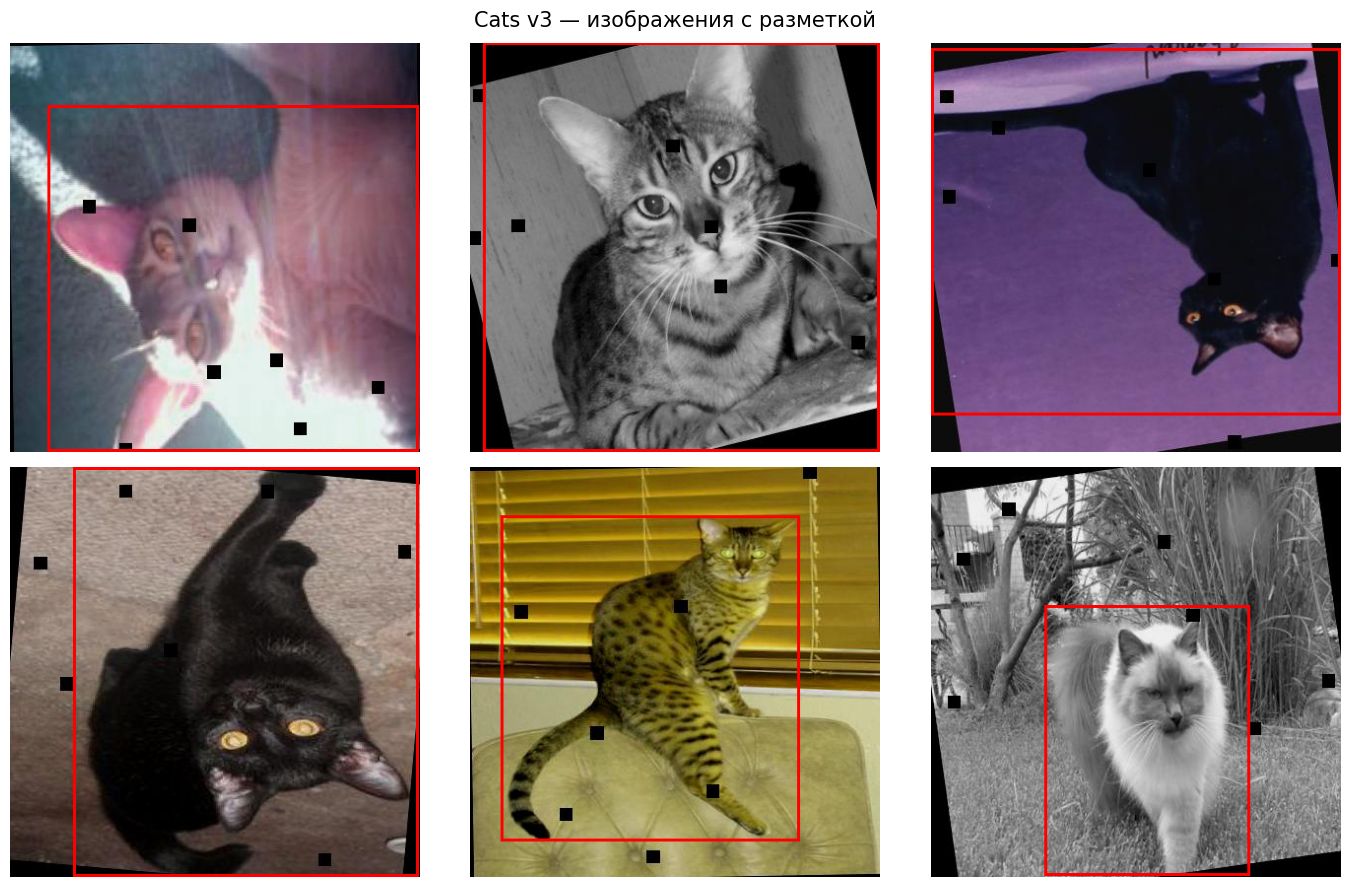

Визуализация сохранена!


In [ ]:

# Визуализация изображений с разметкой

import random
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

train_images = list(splits["train"].glob("*"))

train_images = [
    p for p in train_images
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

random.seed(42)
examples = random.sample(
    train_images,
    min(6, len(train_images))
)

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

names = config["names"]

for ax, path in zip(axes.flat, examples):

    image = Image.open(path).convert("RGB")
    draw = ImageDraw.Draw(image)

    width, height = image.size

    label_path = (
        path.parent.parent /
        "labels" /
        (path.stem + ".txt")
    )

    if label_path.exists():
        for line in label_path.read_text().splitlines():

            values = line.split()

            if len(values) < 5:
                continue

            cls = int(values[0])
            x, y, w, h = map(float, values[1:5])

            x1 = (x - w / 2) * width
            y1 = (y - h / 2) * height
            x2 = (x + w / 2) * width
            y2 = (y + h / 2) * height

            draw.rectangle(
                [x1, y1, x2, y2],
                outline="red",
                width=3
            )

    ax.imshow(image)
    ax.axis("off")

for ax in axes.flat[len(examples):]:
    ax.axis("off")

plt.suptitle(
    "Cats v3 — изображения с разметкой",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "cats_annotated_examples.png",
    dpi=200
)

plt.show()

print("Визуализация сохранена!")


In [7]:

# ЛР3 Яшков П. А. — вариант 4
# Обучение YOLO11s на Cats v3

from ultralytics import YOLO
import torch
from pathlib import Path

assert torch.cuda.is_available(), "GPU T4 не подключён!"
assert DATA_YAML.is_file(), "Не найден data_colab.yaml"

EPOCHS = 30
IMAGE_SIZE = 640
BATCH_SIZE = 16

RUN_DIR = RESULTS_DIR / "training" / "yolo11s_cats_v3"

print("=" * 55)
print("ЛАБОРАТОРНАЯ РАБОТА №3 — ОБУЧЕНИЕ")
print("Модель: YOLO11s")
print("Датасет: Cats v3")
print("GPU:", torch.cuda.get_device_name(0))
print("Эпох:", EPOCHS)
print("Размер изображений:", IMAGE_SIZE)
print("=" * 55)

# Загружаем предобученную YOLO11s
model = YOLO(str(MODEL_PATH))

# Запускаем обучение
train_results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=0,
    workers=0,
    optimizer="auto",
    patience=0,
    save=True,
    save_period=5,
    plots=True,
    project=str(RESULTS_DIR / "training"),
    name="yolo11s_cats_v3",
    exist_ok=True,
    seed=42,
    amp=True
)

print("\nОБУЧЕНИЕ ЗАВЕРШЕНО!")
print("Результаты:", RUN_DIR)
print("Лучшие веса:", RUN_DIR / "weights/best.pt")


ЛАБОРАТОРНАЯ РАБОТА №3 — ОБУЧЕНИЕ
Модель: YOLO11s
Датасет: Cats v3
GPU: Tesla T4
Эпох: 30
Размер изображений: 640
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cats_v3/data_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/con

In [8]:

# ЛР3 Яшков — тестирование YOLO11s

from ultralytics import YOLO
from pathlib import Path
import json
import shutil
import torch

ROOT = Path("/content/drive/MyDrive/OIIS_LR3_Yashkov")
RESULTS_DIR = ROOT / "results"
MODELS_DIR = ROOT / "models"
RUN_DIR = RESULTS_DIR / "training/yolo11s_cats_v3"

DATA_YAML = Path("/content/cats_v3/data_colab.yaml")
BEST_WEIGHTS = RUN_DIR / "weights/best.pt"

assert BEST_WEIGHTS.exists(), "Не найден best.pt!"
assert DATA_YAML.exists(), "Не найден data_colab.yaml!"
assert torch.cuda.is_available(), "Подключи GPU T4!"

# Загружаем лучшую обученную модель
model = YOLO(str(BEST_WEIGHTS))

print("=" * 55)
print("ТЕСТИРОВАНИЕ YOLO11s — CATS V3")
print("=" * 55)

metrics = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    workers=0,
    plots=True,
    project=str(RESULTS_DIR),
    name="test_evaluation",
    exist_ok=True
)

# Сохраняем настоящие метрики
results = {
    "precision": float(metrics.box.mp),
    "recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP75": float(metrics.box.map75),
    "mAP50-95": float(metrics.box.map)
}

with open(
    RESULTS_DIR / "test_metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(results, f, indent=4)

# Отдельная копия лучших весов
MODELS_DIR.mkdir(parents=True, exist_ok=True)

shutil.copy2(
    BEST_WEIGHTS,
    MODELS_DIR / "yolo11s_cats_best.pt"
)

print("\n========== РЕЗУЛЬТАТЫ ТЕСТА ==========")

for name, value in results.items():
    print(f"{name}: {value:.4f} ({value*100:.2f}%)")

print("\nМетрики и графики сохранены!")
print("Папка:", RESULTS_DIR / "test_evaluation")


ТЕСТИРОВАНИЕ YOLO11s — CATS V3
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 8.2±6.0 MB/s, size: 23.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/cats_v3/test/labels... 116 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 116/116 377.0it/s 0.3s
val: New cache created: /content/cats_v3/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.0it/s 2.7s
                   all        116        116      0.909      0.946      0.959       0.58
Speed: 0.6ms preprocess, 10.0ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to /content/drive/MyDrive/OIIS_LR3_Yashkov/results/test_evaluation

====

РЕЗУЛЬТАТЫ ОБУЧЕНИЯ YOLO11s

Последние 10 эпох:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
20,21,1301.08,0.78203,0.47585,1.65489,0.93123,0.90213,0.93321,0.50332,1.58994,0.75533,2.31718,0.000680,0.000680,0.000680
21,22,1359.95,0.75273,0.45141,1.61609,0.89832,0.90638,0.90859,0.48568,1.65255,0.78313,2.46422,0.000614,0.000614,0.000614
22,23,1417.22,0.74677,0.42037,1.62308,0.91528,0.91489,0.92443,0.50783,1.65744,0.72997,2.43078,0.000548,0.000548,0.000548
23,24,1473.96,0.72948,0.41823,1.60181,0.87261,0.87660,0.85888,0.44905,1.56524,0.79253,2.49223,0.000482,0.000482,0.000482
24,25,1530.48,0.69449,0.39418,1.56416,0.92664,0.91064,0.93498,0.50221,1.64223,0.70844,2.42363,0.000416,0.000416,0.000416
25,26,1587.65,0.70459,0.42482,1.53938,0.91384,0.92340,0.93470,0.52239,1.54302,0.67657,2.31893,0.000350,0.000350,0.000350
26,27,1645.70,0.68450,0.38638,1.52564,0.93415,0.91915,0.94491,0.56318,1.41800,0.66068,2.12424,0.000284,0.000284,0.000284
27,28,1707.27,0.63240,0.36836,1.48441,0.96101,0.94398,0.96266,0.56237,1.45604,0.63732,2.20290,0.000218,0.000218,0.000218
28,29,1766.81,0.62826,0.35915,1.45542,0.93068,0.91415,0.94043,0.56286,1.40525,0.66699,2.14134,0.000152,0.000152,0.000152
29,30,1826.28,0.60644,0.35719,1.45226,0.94547,0.91915,0.93361,0.55509,1.42205,0.65929,2.16967,0.000086,0.000086,0.000086



Графики обучения:


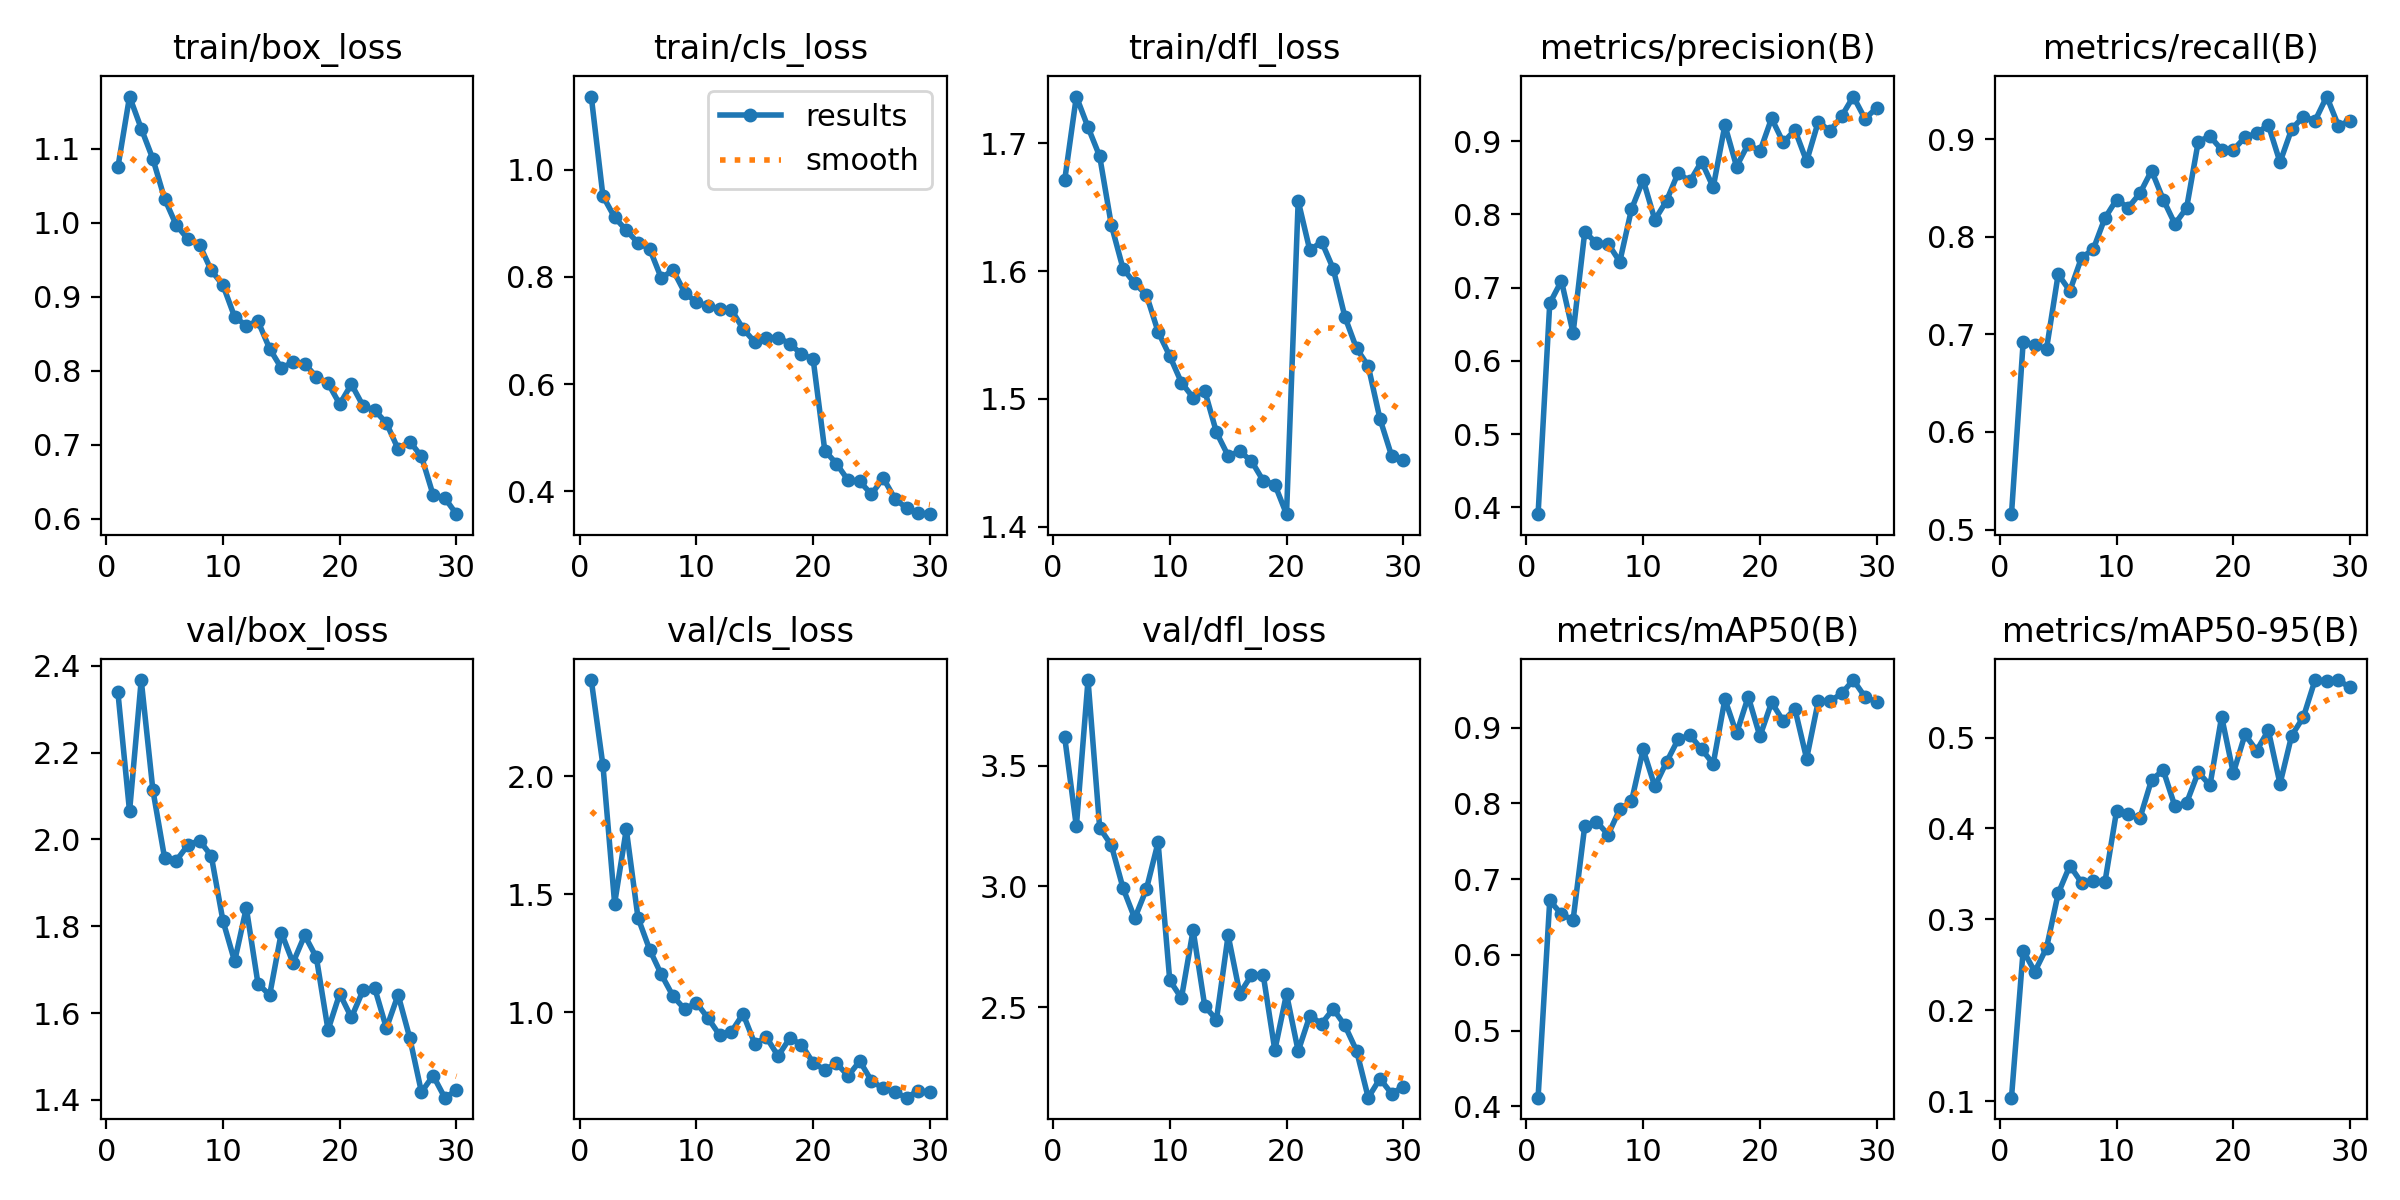


График: BoxPR_curve.png


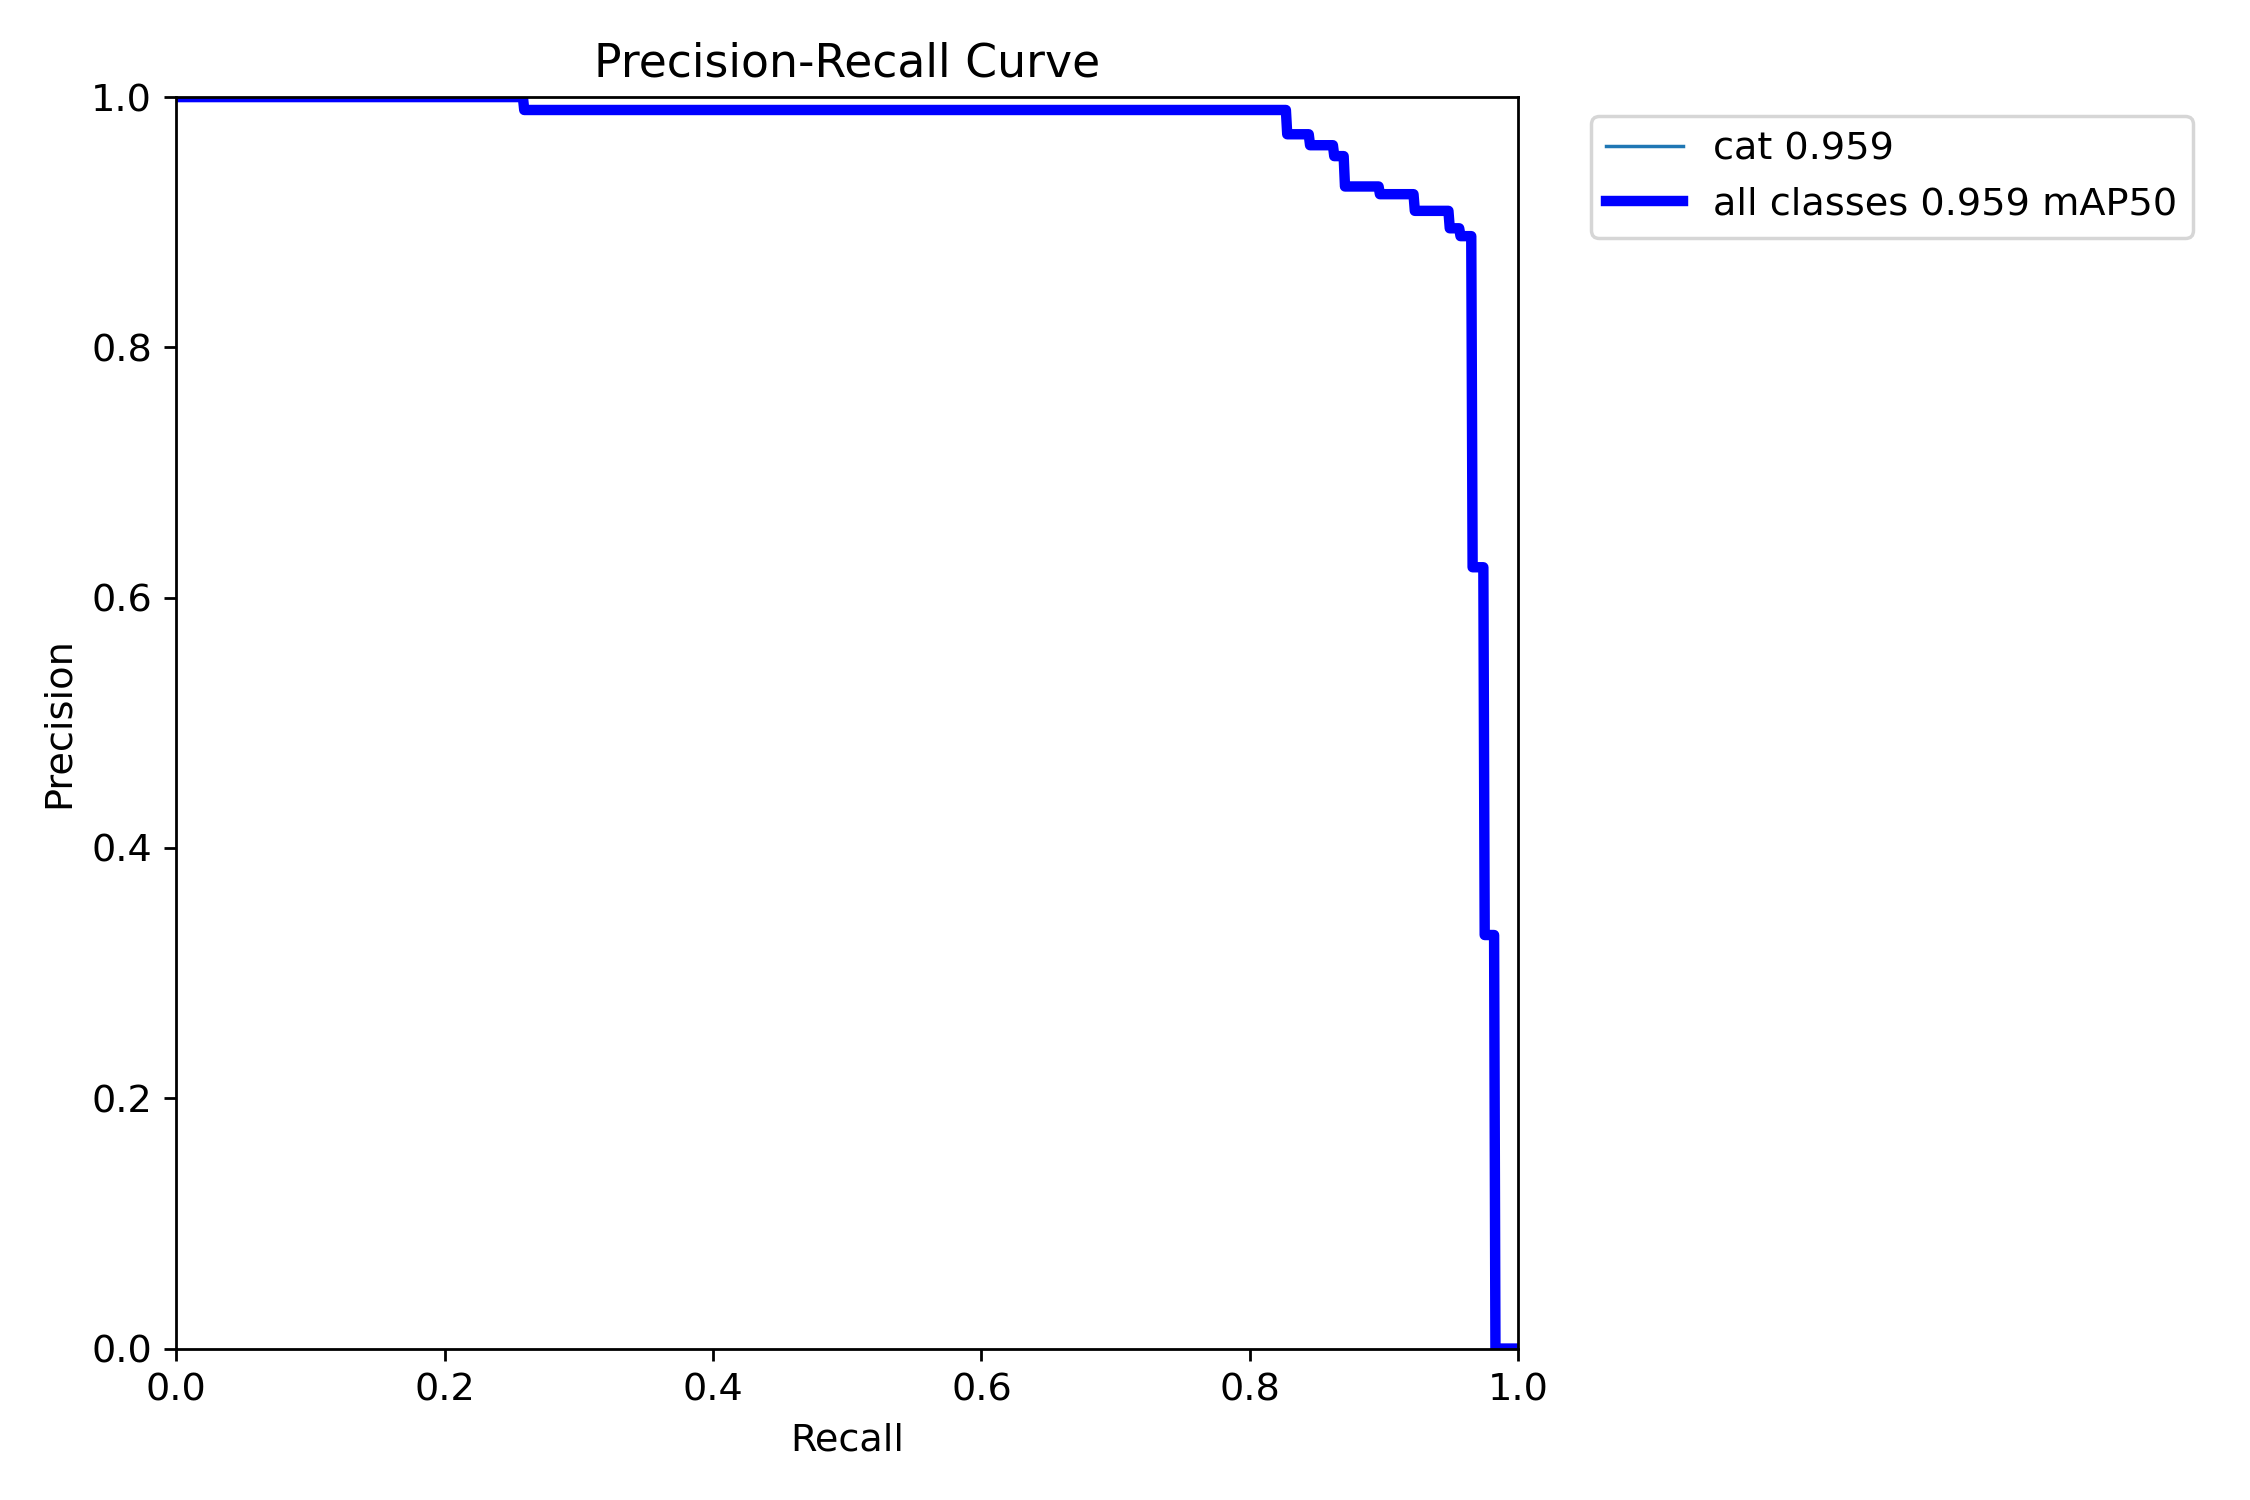


График: BoxF1_curve.png


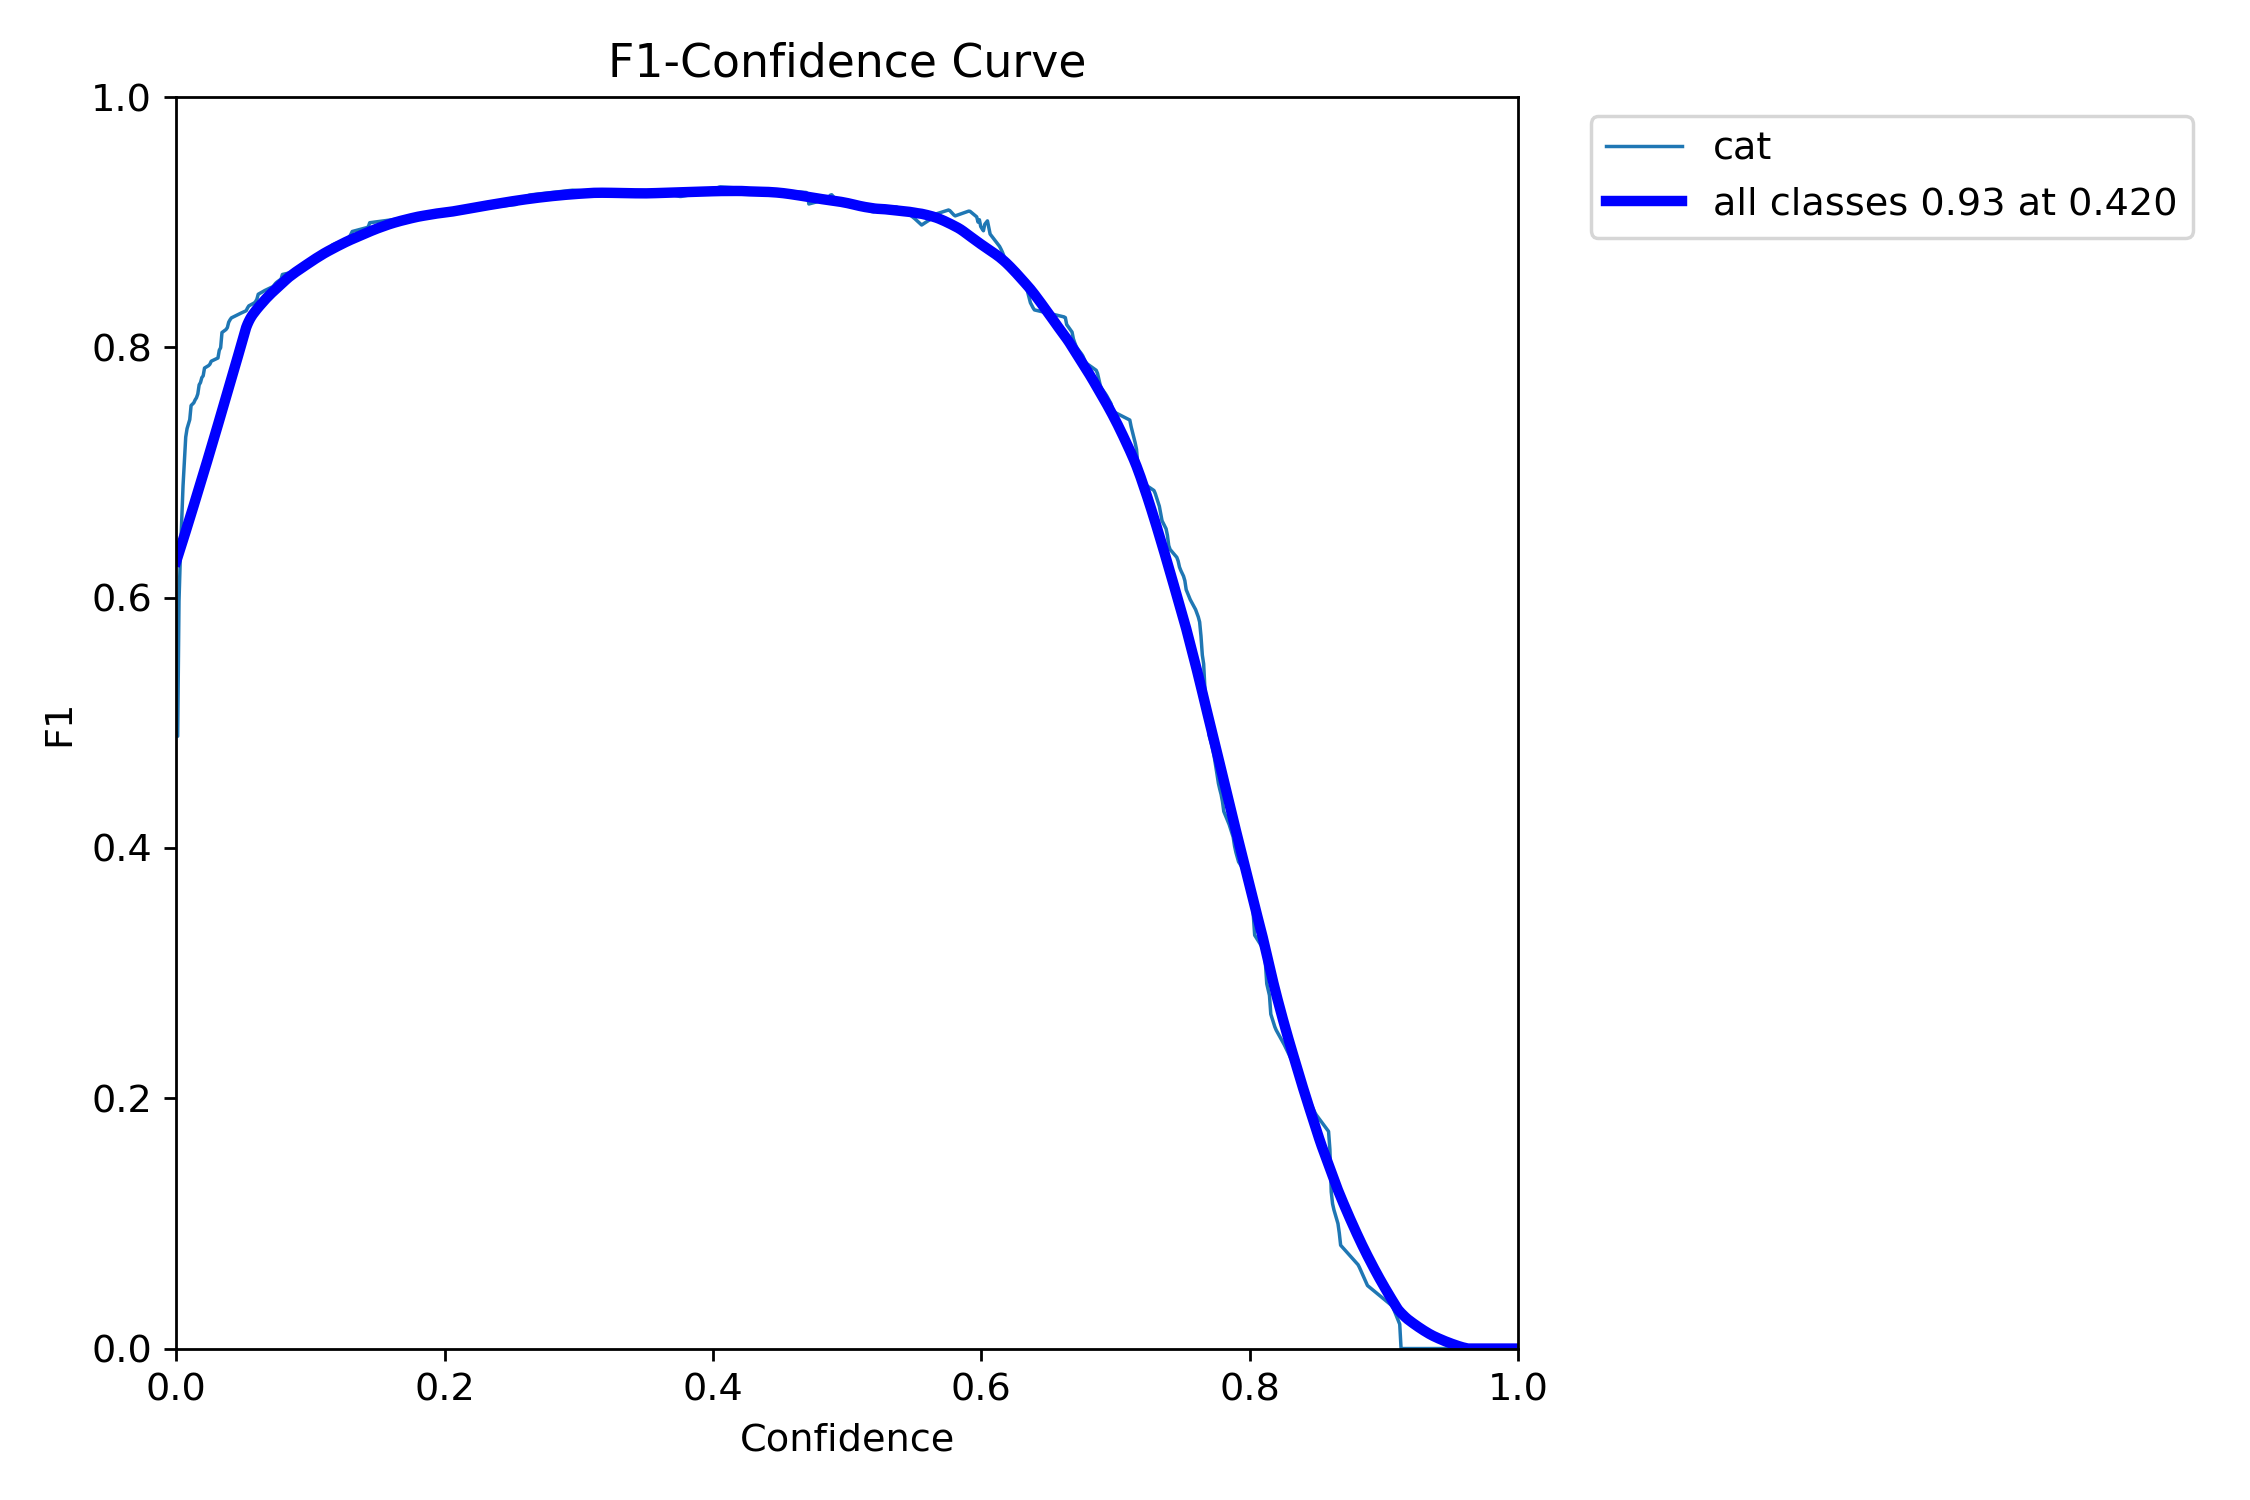


График: confusion_matrix.png


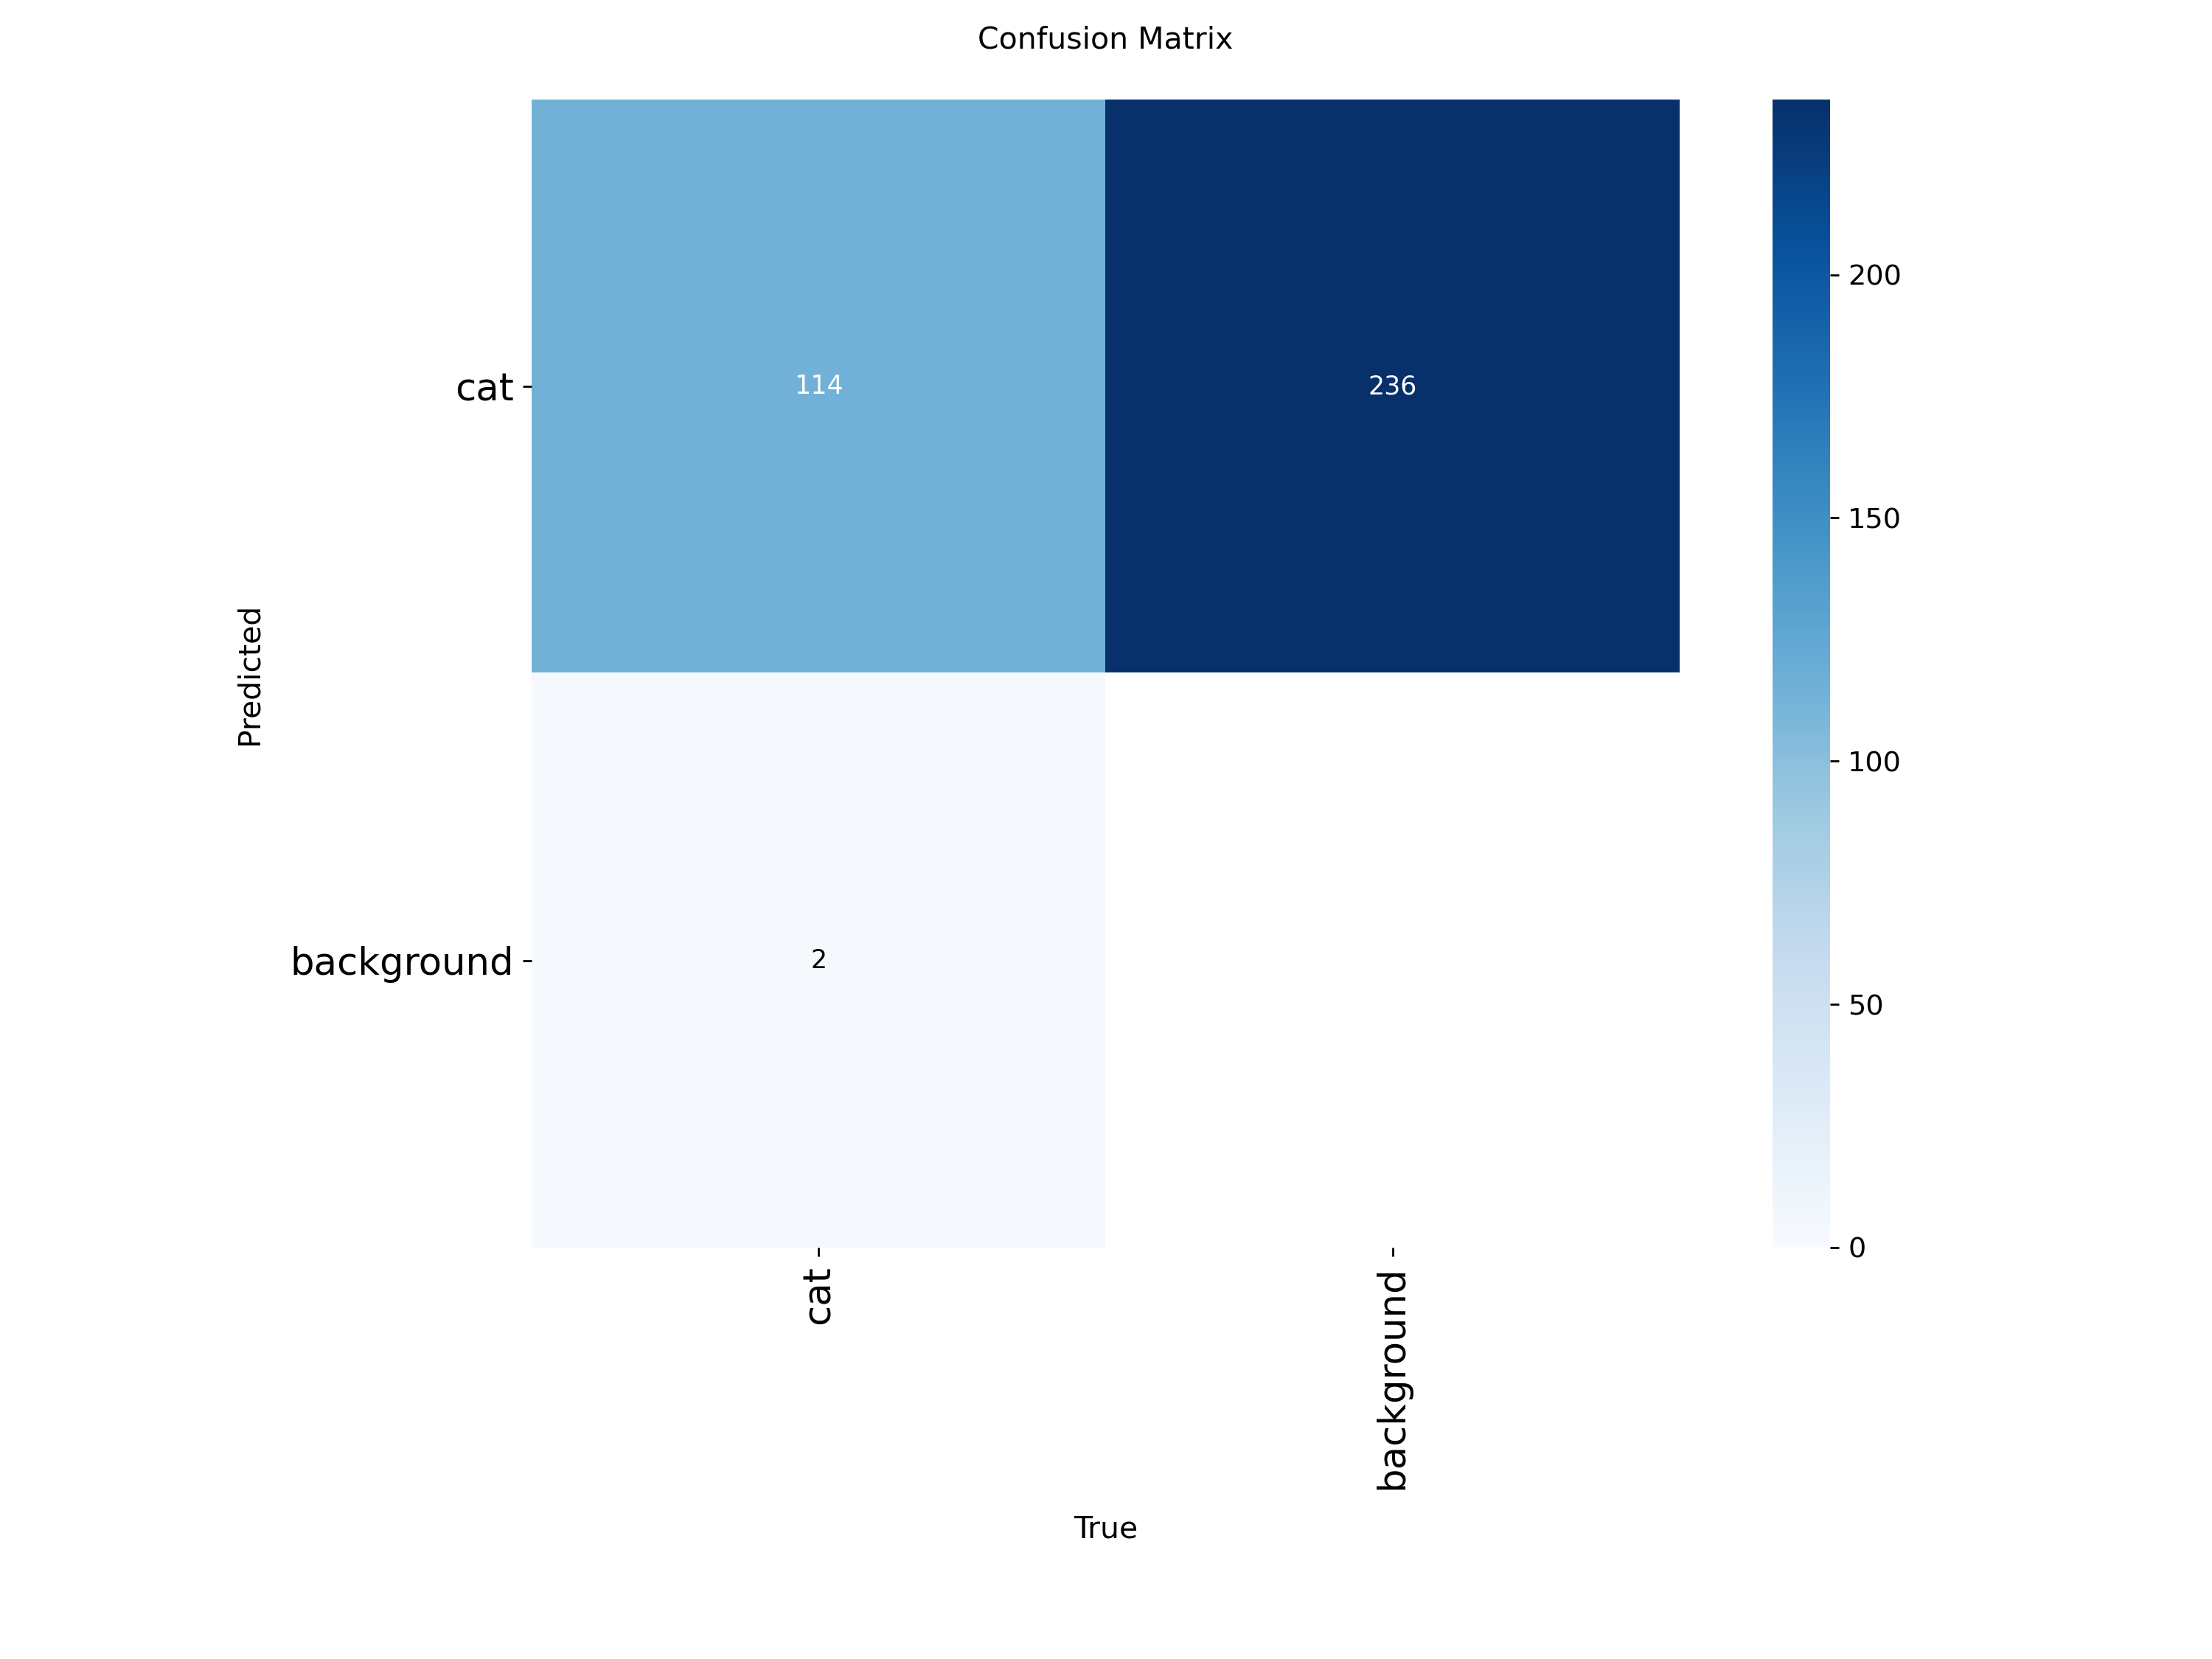


График: confusion_matrix_normalized.png


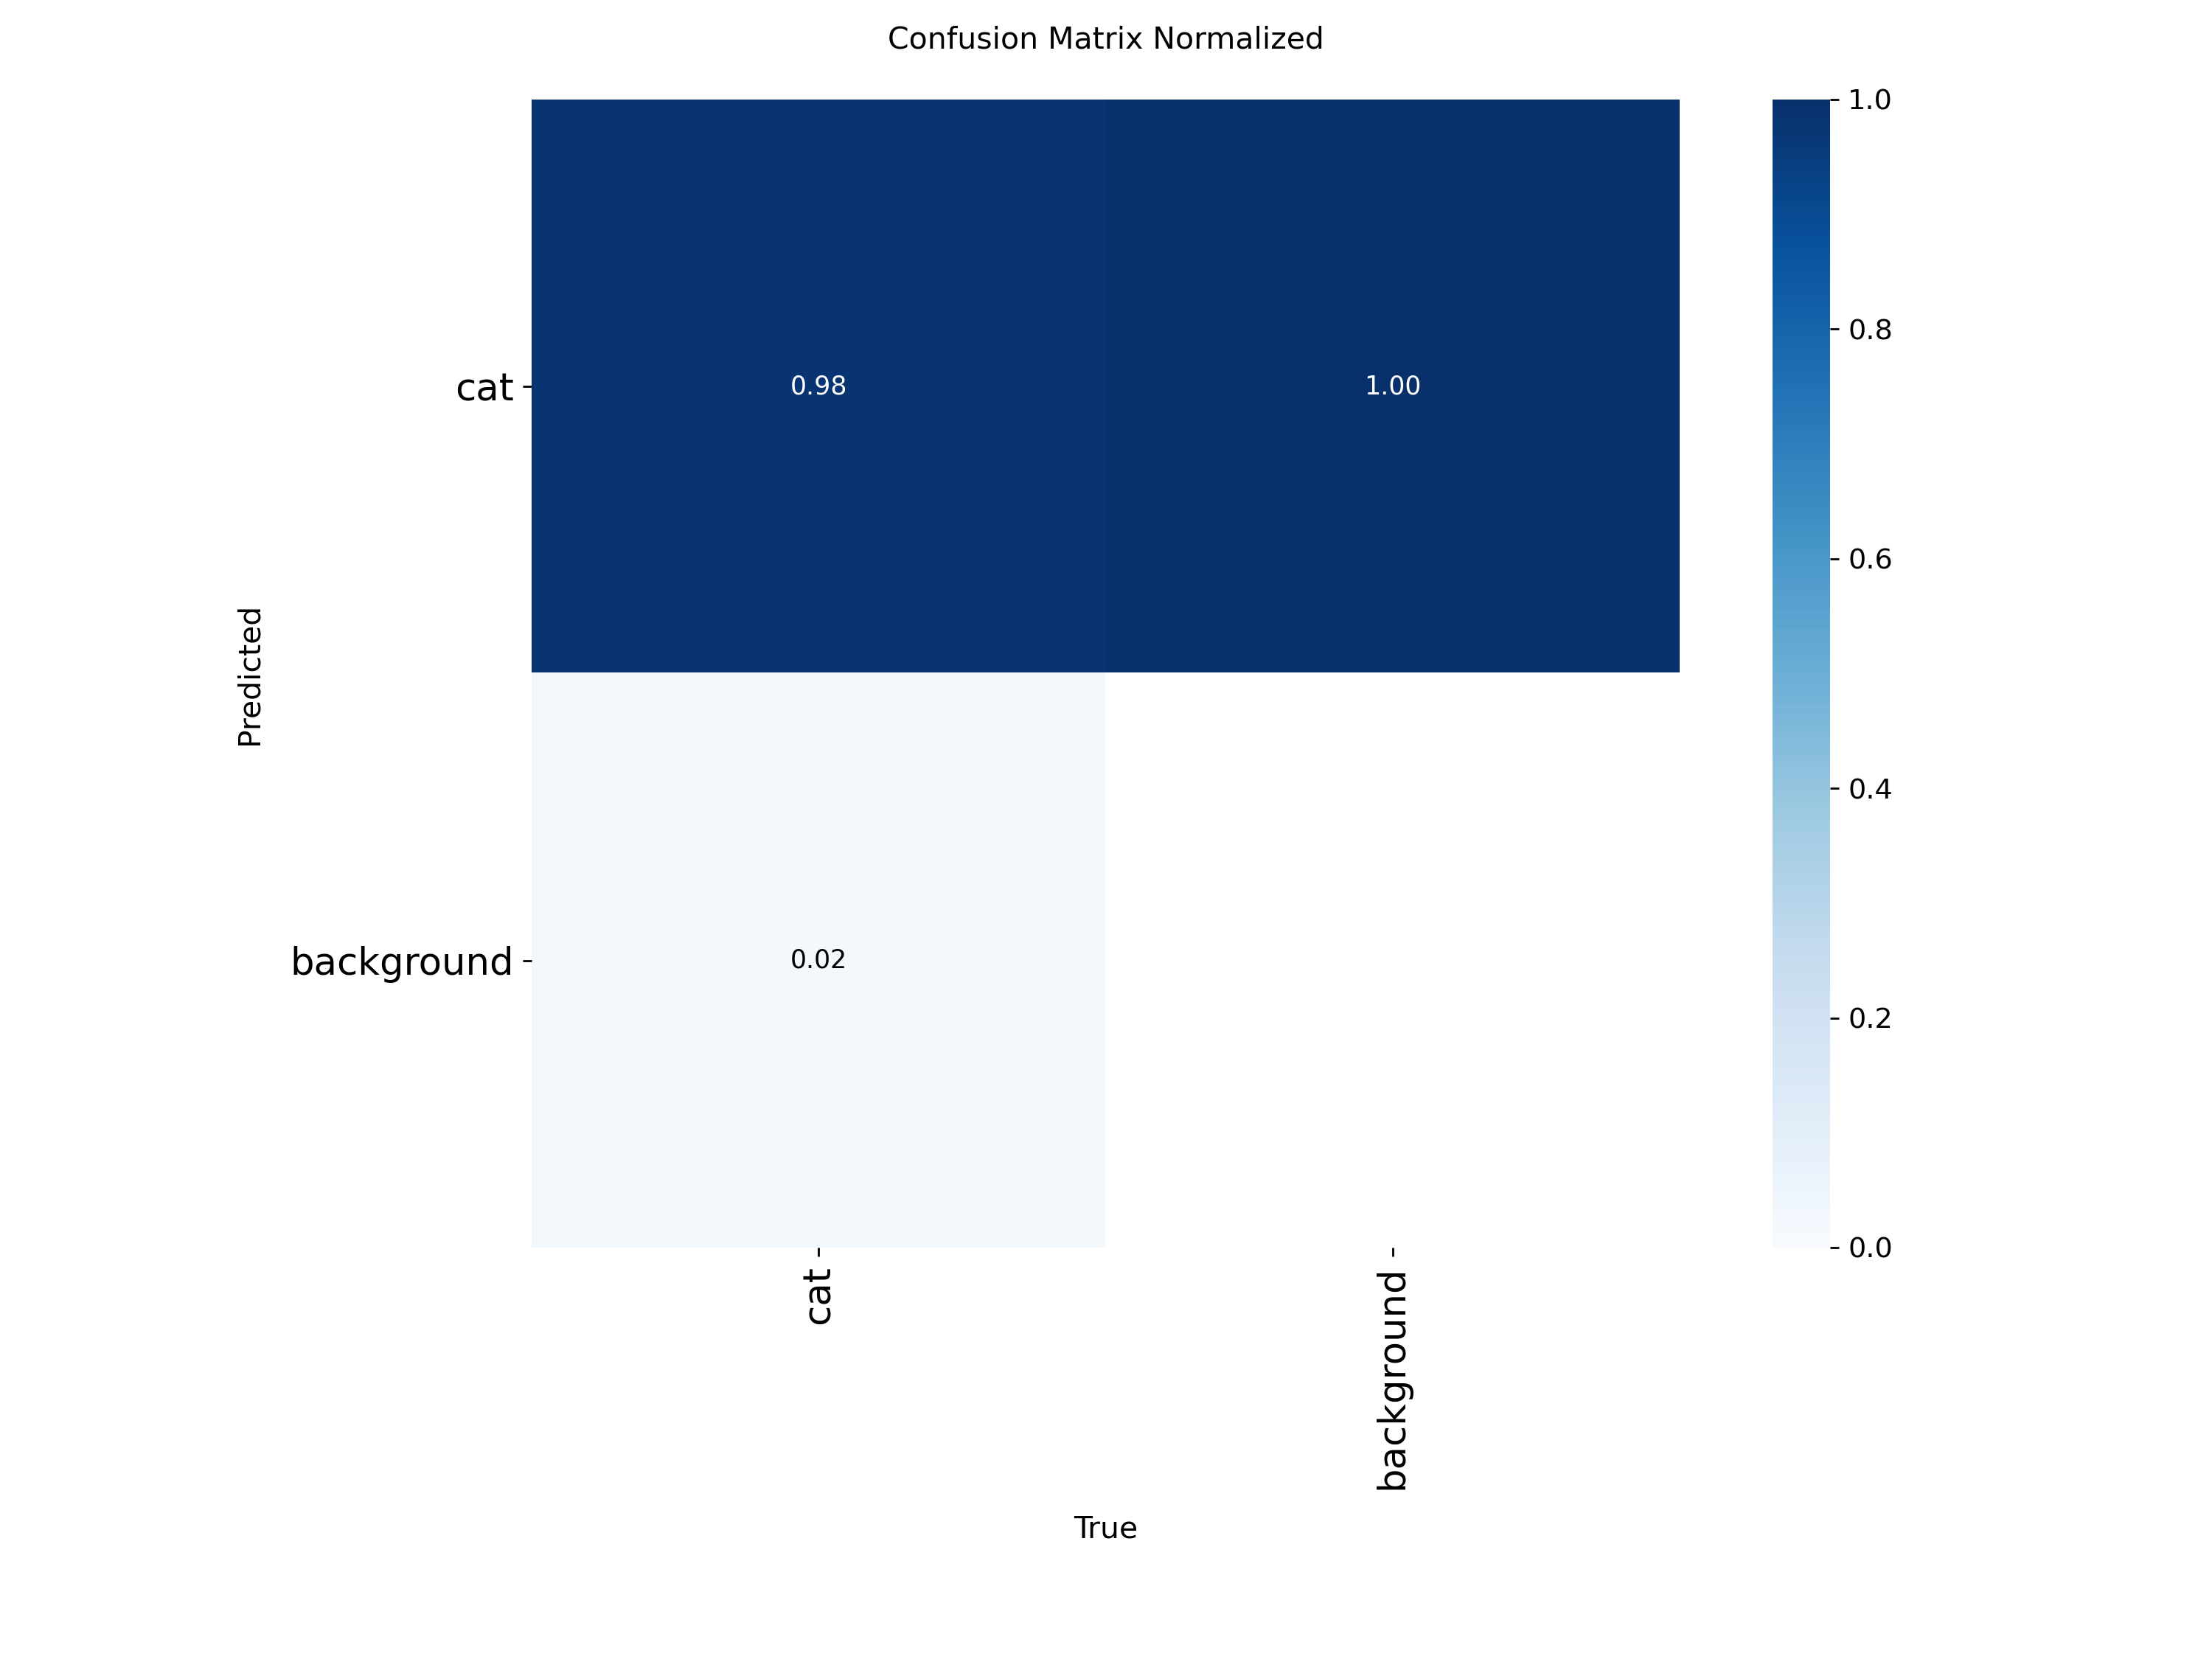


ПРОВЕРКА ЗАВЕРШЕНА!
Результаты сохранены на Google Drive.


In [9]:

# Вывод графиков и истории обучения

import pandas as pd
from IPython.display import display, Image

print("РЕЗУЛЬТАТЫ ОБУЧЕНИЯ YOLO11s")

history_path = RUN_DIR / "results.csv"
training_plot = RUN_DIR / "results.png"
test_dir = RESULTS_DIR / "test_evaluation"

# Таблица эпох
if history_path.exists():
    df = pd.read_csv(history_path)
    df.columns = df.columns.str.strip()

    print("\nПоследние 10 эпох:")
    display(df.tail(10))

# Основные графики обучения
if training_plot.exists():
    print("\nГрафики обучения:")
    display(Image(filename=str(training_plot)))

# Графики тестирования
plots = [
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png"
]

for filename in plots:
    path = test_dir / filename

    if path.exists():
        print("\nГрафик:", filename)
        display(Image(filename=str(path)))

print("\nПРОВЕРКА ЗАВЕРШЕНА!")
print("Результаты сохранены на Google Drive.")


In [1]:

# ЭТАП 10 — Подготовка интернет-изображений

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/OIIS_LR3_Yashkov")
IMAGES_DIR = ROOT / "internet_images"

IMAGES_DIR.mkdir(parents=True, exist_ok=True)

images = sorted([
    p for p in IMAGES_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

print("=" * 55)
print("ПРОВЕРКА ИЗОБРАЖЕНИЙ ИЗ ИНТЕРНЕТА")
print("=" * 55)

print("Найдено изображений:", len(images))

for image in images:
    print("OK:", image.name)

assert images, "Загрузи фотографии в internet_images!"

print("\nФотографии готовы к распознаванию!")


ПРОВЕРКА ИЗОБРАЖЕНИЙ ИЗ ИНТЕРНЕТА
Найдено изображений: 0


AssertionError: Загрузи фотографии в internet_images!

In [3]:

from google.colab import drive
from pathlib import Path

# Переподключаем Google Drive
drive.mount("/content/drive", force_remount=True)

ROOT = Path("/content/drive/MyDrive/OIIS_LR3_Yashkov")
IMAGES_DIR = ROOT / "internet_images"
RESULTS_DIR = ROOT / "results"

print("=" * 55)
print("ПРОВЕРКА ФОТОГРАФИЙ")
print("=" * 55)

print("Папка проекта существует:", ROOT.exists())
print("Папка фотографий существует:", IMAGES_DIR.exists())

images = sorted([
    p for p in IMAGES_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

print("\nНайдено фотографий:", len(images))

for image in images:
    print("OK:", image.name)

assert len(images) > 0, (
    "Фотографии не найдены. Проверь подключённый "
    "Google-аккаунт и папку на Диске."
)

print("\nВСЕ ФОТОГРАФИИ НАЙДЕНЫ!")


ValueError: Mountpoint must not already contain files

In [6]:

# Восстановление среды после перезапуска Colab

%pip install -q ultralytics pyyaml

import torch
from ultralytics import YOLO
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive", force_remount=False)

ROOT = Path("/content/drive/MyDrive/OIIS_LR3_Yashkov")
DATA_DIR = ROOT / "dataset"
MODELS_DIR = ROOT / "models"
RESULTS_DIR = ROOT / "results"
PLOTS_DIR = RESULTS_DIR / "plots"

for folder in [MODELS_DIR, RESULTS_DIR, PLOTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODELS_DIR / "yolo11s_pretrained.pt"

SOURCE = (
    DATA_DIR /
    "Cats.v3-augmented-v1-accurate.yolov11"
)

LOCAL = Path("/content/cats_v3")

import shutil

# Восстанавливаем датасет на локальном диске Colab
if not (LOCAL / "data_colab.yaml").exists():
    print("Восстанавливаем датасет...")
    assert SOURCE.exists(), "Исходный датасет не найден!"
    shutil.copytree(SOURCE, LOCAL, dirs_exist_ok=True)

    import yaml
    yaml_files = list(LOCAL.rglob("data.yaml"))
    assert yaml_files, "data.yaml не найден!"

    dataset_root = yaml_files[0].parent

    with open(yaml_files[0], encoding="utf-8") as f:
        config = yaml.safe_load(f)

    config["path"] = str(dataset_root)
    config["train"] = str(dataset_root / "train/images")
    config["val"] = str(dataset_root / "valid/images")
    config["test"] = str(dataset_root / "test/images")

    with open(LOCAL / "data_colab.yaml", "w") as f:
        yaml.safe_dump(config, f)

DATA_YAML = LOCAL / "data_colab.yaml"

# Проверяем файлы перед обучением
assert DATA_YAML.exists(), "Нет конфигурации датасета!"
assert MODEL_PATH.exists(), "Не найдены веса YOLO11s!"
assert torch.cuda.is_available(), "GPU T4 не подключена!"

print("=" * 55)
print("Ultralytics установлен!")
print("GPU:", torch.cuda.get_device_name(0))
print("Датасет:", DATA_YAML)
print("Модель:", MODEL_PATH)
print("СРЕДА ВОССТАНОВЛЕНА!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Mounted at /content/drive
Восстанавливаем датасет...
Ultralytics установлен!
GPU: Tesla T4
Датасет: /content/cats_v3/data_colab.yaml
Модель: /content/drive/MyDrive/OIIS_LR3_Yashkov/models/yolo11s_pretrained.pt
СРЕДА ВОССТАНОВЛЕНА!


In [4]:

from google.colab import drive
from pathlib import Path

# Используем существующее подключение, если оно работает
MOUNT = Path("/content/drive")

if not (MOUNT / "MyDrive").is_dir():
    MOUNT = Path("/content/drive_lr3")
    drive.mount(str(MOUNT))

ROOT = MOUNT / "MyDrive" / "OIIS_LR3_Yashkov"
IMAGES_DIR = ROOT / "internet_images"
RESULTS_DIR = ROOT / "results"

print("Google Drive:", MOUNT)
print("Папка проекта:", ROOT.exists())
print("Папка фотографий:", IMAGES_DIR.exists())

images = sorted([
    p for p in IMAGES_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]) if IMAGES_DIR.exists() else []

print("\nНайдено фотографий:", len(images))

for img in images:
    print("OK:", img.name)

if not images:
    print("\nСодержимое папки проекта:")
    if ROOT.exists():
        print([p.name for p in ROOT.iterdir()])
    print("Проверь аккаунт и расположение фотографий.")
else:
    print("\nВСЕ ФОТОГРАФИИ НАЙДЕНЫ!")


Google Drive: /content/drive
Папка проекта: True
Папка фотографий: True

Найдено фотографий: 0

Содержимое папки проекта:
['internet_images']
Проверь аккаунт и расположение фотографий.


In [5]:

from google.colab import drive
from pathlib import Path

# Используем новый путь, чтобы избежать ошибки подключения
MOUNT = Path("/content/gdrive_yashkov")
MOUNT.mkdir(parents=True, exist_ok=True)

drive.mount(str(MOUNT))

ROOT = MOUNT / "MyDrive" / "OIIS_LR3_Yashkov"
IMAGES_DIR = ROOT / "internet_images"
RESULTS_DIR = ROOT / "results"

print("\nПРОВЕРКА GOOGLE DRIVE")
print("=" * 50)
print("Папка проекта существует:", ROOT.exists())

if ROOT.exists():
    print("\nСодержимое проекта:")
    for item in ROOT.iterdir():
        print(" -", item.name)

images = sorted([
    p for p in IMAGES_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in
    [".jpg", ".jpeg", ".png"]
]) if IMAGES_DIR.exists() else []

print("\nНайдено фотографий:", len(images))

for img in images:
    print("OK:", img.name)

BEST_WEIGHTS = (
    RESULTS_DIR /
    "training/yolo11s_cats_v3/weights/best.pt"
)

print("\nОбученная модель найдена:", BEST_WEIGHTS.exists())

if images and BEST_WEIGHTS.exists():
    print("\nВСЁ ГОТОВО К РАСПОЗНАВАНИЮ!")
else:
    print("\nНе все данные обнаружены. Проверь вывод выше.")


Mounted at /content/gdrive_yashkov

ПРОВЕРКА GOOGLE DRIVE
Папка проекта существует: True

Содержимое проекта:
 - dataset
 - models
 - results
 - internet_images
 - LR3_Yashkov.ipynb

Найдено фотографий: 5
OK: photo_2026-11-24_09-17-18 (2).jpg
OK: photo_2026-11-24_09-17-18 (3).jpg
OK: photo_2026-11-24_09-17-18 (4).jpg
OK: photo_2026-11-24_09-17-18.jpg
OK: photo_2026-11-24_09-17-19.jpg

Обученная модель найдена: True

ВСЁ ГОТОВО К РАСПОЗНАВАНИЮ!


In [6]:

from ultralytics import YOLO
from IPython.display import display, Image
import torch

assert len(images) > 0, "Фотографии не найдены!"
assert BEST_WEIGHTS.exists(), "Модель не найдена!"

model = YOLO(str(BEST_WEIGHTS))

results = model.predict(
    source=str(IMAGES_DIR),
    imgsz=640,
    conf=0.25,
    device=0 if torch.cuda.is_available() else "cpu",
    save=True,
    save_txt=True,
    save_conf=True,
    project=str(RESULTS_DIR),
    name="internet_predictions",
    exist_ok=True
)

for result in results:
    print("\nФайл:", Path(result.path).name)
    print("Обнаружено котов:", len(result.boxes))

    for box in result.boxes:
        print(f"Уверенность: {float(box.conf[0]):.2%}")

    display(
        Image(
            data=result.plot()[:, :, ::-1].tobytes(),
            # Визуализацию покажем через PIL ниже
        )
    )


ModuleNotFoundError: No module named 'ultralytics'

In [7]:
%pip install -q ultralytics

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
ЛАБОРАТОРНАЯ РАБОТА №3
Яшков П. А. — Вариант №4
YOLO11s — обнаружение котов
Устройство: cpu
Фотографий: 5

0: 640x640 1 cat, 686.8ms
1: 640x640 1 cat, 686.8ms
2: 640x640 2 cats, 686.8ms
3: 640x640 1 cat, 686.8ms
4: 640x640 1 cat, 686.8ms
Speed: 13.1ms preprocess, 686.8ms inference, 5.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/gdrive_yashkov/MyDrive/OIIS_LR3_Yashkov/results/internet_predictions
5 labels saved to /content/gdrive_yashkov/MyDrive/OIIS_LR3_Yashkov/results/internet_predictions/labels

РЕЗУЛЬТАТЫ РАСПОЗНАВАНИЯ

Фотография: photo_2026-11-24_09-17-18 (2).jpg
Обнаружено котов: 1
Уверенность: 63.75%


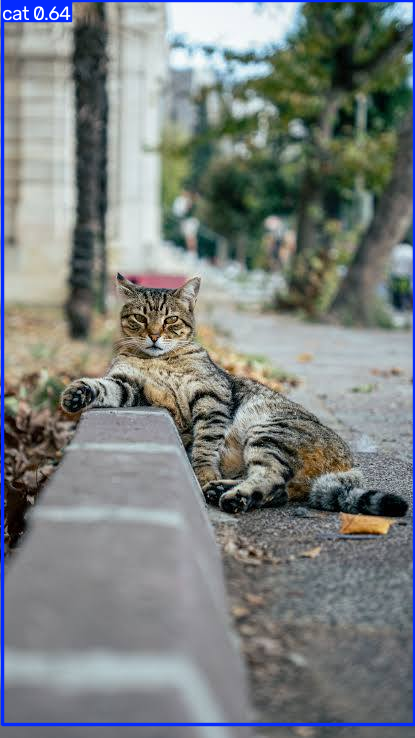


Фотография: photo_2026-11-24_09-17-18 (3).jpg
Обнаружено котов: 1
Уверенность: 57.03%


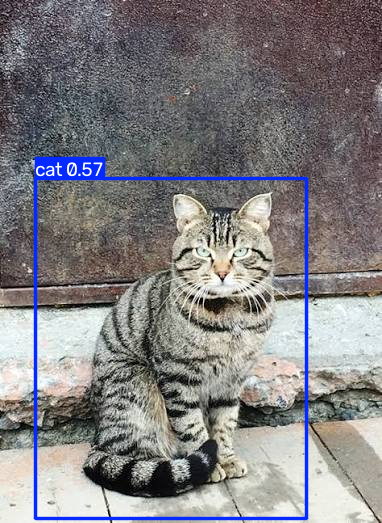


Фотография: photo_2026-11-24_09-17-18 (4).jpg
Обнаружено котов: 2
Уверенность: 70.55%
Уверенность: 31.62%


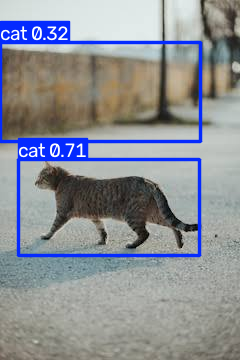


Фотография: photo_2026-11-24_09-17-18.jpg
Обнаружено котов: 1
Уверенность: 53.02%


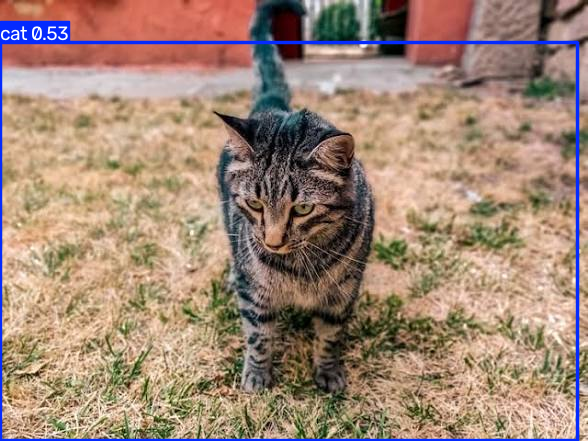


Фотография: photo_2026-11-24_09-17-19.jpg
Обнаружено котов: 1
Уверенность: 76.43%


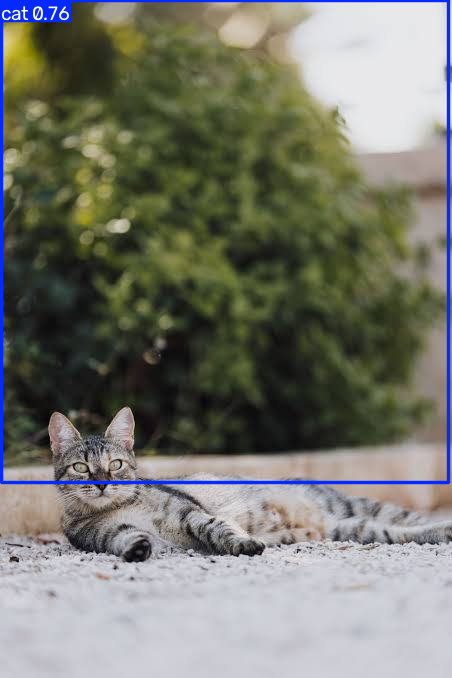


ВСЕ 5 ФОТОГРАФИЙ ОБРАБОТАНЫ!
Результаты сохранены на Google Drive!
Папка: /content/gdrive_yashkov/MyDrive/OIIS_LR3_Yashkov/results/internet_predictions


In [8]:

# ЛР3 Яшков П. А. — Вариант 4
# Распознавание котов на фотографиях из Интернета

from ultralytics import YOLO
from pathlib import Path
from PIL import Image
from IPython.display import display
import torch

ROOT = Path(
    "/content/gdrive_yashkov/MyDrive/OIIS_LR3_Yashkov"
)

IMAGES_DIR = ROOT / "internet_images"
RESULTS_DIR = ROOT / "results"

BEST_WEIGHTS = (
    RESULTS_DIR /
    "training/yolo11s_cats_v3/weights/best.pt"
)

images = sorted(
    p for p in IMAGES_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

assert images, "Фотографии не найдены!"
assert BEST_WEIGHTS.exists(), "Модель best.pt не найдена!"

# Загружаем обученную модель
model = YOLO(str(BEST_WEIGHTS))

device = 0 if torch.cuda.is_available() else "cpu"

print("=" * 55)
print("ЛАБОРАТОРНАЯ РАБОТА №3")
print("Яшков П. А. — Вариант №4")
print("YOLO11s — обнаружение котов")
print("=" * 55)

print("Устройство:", device)
print("Фотографий:", len(images))

# Запускаем распознавание
results = model.predict(
    source=[str(p) for p in images],
    imgsz=640,
    conf=0.25,
    device=device,
    save=True,
    save_txt=True,
    save_conf=True,
    project=str(RESULTS_DIR),
    name="internet_predictions",
    exist_ok=True
)

# Выводим полученные результаты
print("\nРЕЗУЛЬТАТЫ РАСПОЗНАВАНИЯ")

for result in results:

    print("\n" + "=" * 45)
    print("Фотография:", Path(result.path).name)
    print("Обнаружено котов:", len(result.boxes))

    for box in result.boxes:
        confidence = float(box.conf[0])

        print(
            f"Уверенность: {confidence * 100:.2f}%"
        )

    # Правильное отображение изображения
    annotated = result.plot()
    annotated_rgb = annotated[:, :, ::-1]

    display(Image.fromarray(annotated_rgb))

print("\nВСЕ 5 ФОТОГРАФИЙ ОБРАБОТАНЫ!")
print("Результаты сохранены на Google Drive!")
print(
    "Папка:",
    RESULTS_DIR / "internet_predictions"
)


In [9]:

# ЛР3 — Итоговая таблица распознавания
# Яшков П. А., вариант 4

from pathlib import Path
import pandas as pd

ROOT = Path(
    "/content/gdrive_yashkov/MyDrive/OIIS_LR3_Yashkov"
)

IMAGES_DIR = ROOT / "internet_images"
RESULTS_DIR = ROOT / "results"
PRED_DIR = RESULTS_DIR / "internet_predictions"
LABELS_DIR = PRED_DIR / "labels"

rows = []

for image in sorted(IMAGES_DIR.iterdir()):
    if image.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
        continue

    label_file = LABELS_DIR / (image.stem + ".txt")

    confidences = []

    if label_file.exists():
        for line in label_file.read_text().splitlines():
            values = line.split()

            if len(values) >= 6:
                confidences.append(float(values[5]))

    rows.append({
        "Изображение": image.name,
        "Обнаружено котов": len(confidences),
        "Макс. уверенность, %": (
            round(max(confidences) * 100, 2)
            if confidences else 0
        )
    })

df = pd.DataFrame(rows)

print("ИТОГИ РАСПОЗНАВАНИЯ КОТОВ")
print("=" * 55)

display(df)

output = RESULTS_DIR / "internet_results.csv"
df.to_csv(output, index=False, encoding="utf-8-sig")

print("\nВсего фотографий:", len(df))
print("Всего обнаружений:", df["Обнаружено котов"].sum())
print("\nТаблица сохранена:", output)
print("\nИТОГОВАЯ ПРОВЕРКА ЗАВЕРШЕНА!")


ИТОГИ РАСПОЗНАВАНИЯ КОТОВ


,Изображение,Обнаружено котов,"Макс. уверенность, %"
0,photo_2026-11-24_09-17-18 (2).jpg,1,63.75
1,photo_2026-11-24_09-17-18 (3).jpg,1,57.03
2,photo_2026-11-24_09-17-18 (4).jpg,2,70.55
3,photo_2026-11-24_09-17-18.jpg,1,53.02
4,photo_2026-11-24_09-17-19.jpg,1,76.43



Всего фотографий: 5
Всего обнаружений: 6

Таблица сохранена: /content/gdrive_yashkov/MyDrive/OIIS_LR3_Yashkov/results/internet_results.csv

ИТОГОВАЯ ПРОВЕРКА ЗАВЕРШЕНА!


In [10]:

from pathlib import Path

ROOT = Path(
    "/content/gdrive_yashkov/MyDrive/OIIS_LR3_Yashkov"
)

files = {
    "Графики обучения": ROOT / "results/training/yolo11s_cats_v3/results.png",
    "История обучения": ROOT / "results/training/yolo11s_cats_v3/results.csv",
    "Лучшая модель": ROOT / "results/training/yolo11s_cats_v3/weights/best.pt",
    "Метрики тестирования": ROOT / "results/test_metrics.json",
    "Матрица ошибок": ROOT / "results/test_evaluation/confusion_matrix.png",
    "PR-кривая": ROOT / "results/test_evaluation/BoxPR_curve.png",
    "Таблица распознавания": ROOT / "results/internet_results.csv",
    "Colab-блокнот": ROOT / "LR3_Yashkov.ipynb"
}

print("ФИНАЛЬНАЯ ПРОВЕРКА ЛР3\n")

for name, path in files.items():
    status = "OK" if path.is_file() else "НЕ НАЙДЕН"
    print(f"{name}: {status}")

pred_dir = ROOT / "results/internet_predictions"

pred_images = [
    p for p in pred_dir.glob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

print("\nОбработанных фотографий:", len(pred_images))
print("Проверка завершена!")


ФИНАЛЬНАЯ ПРОВЕРКА ЛР3

Графики обучения: OK
История обучения: OK
Лучшая модель: OK
Метрики тестирования: OK
Матрица ошибок: OK
PR-кривая: OK
Таблица распознавания: OK
Colab-блокнот: OK

Обработанных фотографий: 5
Проверка завершена!
